# Decision Tree Classification – Heart Disease Dataset



In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

In [17]:
# TASK 1 – DATA PREPARATION

In [18]:
df = pd.read_excel('heart_disease.xlsx', sheet_name='Heart_disease')

print("=" * 60)
print("TASK 1 – DATA PREPARATION")
print("=" * 60)
print(f"\nDataset Shape : {df.shape}  ({df.shape[0]} rows, {df.shape[1]} columns)")
print("\nFirst 5 rows:")
print(df.head())
print("\nData Types:")
print(df.dtypes)

TASK 1 – DATA PREPARATION

Dataset Shape : (908, 13)  (908 rows, 13 columns)

First 5 rows:
   age   sex               cp  trestbps  chol    fbs         restecg  thalch  \
0   63  Male   typical angina       145   233   True  lv hypertrophy     150   
1   41  Male  atypical angina       135   203  False          normal     132   
2   57  Male     asymptomatic       140   192  False          normal     148   
3   52  Male   typical angina       118   186  False  lv hypertrophy     190   
4   57  Male     asymptomatic       110   201  False          normal     126   

   exang  oldpeak        slope          thal  num  
0  False      2.3  downsloping  fixed defect    0  
1  False      0.0         flat  fixed defect    0  
2  False      0.4         flat  fixed defect    0  
3  False      0.0         flat  fixed defect    0  
4   True      1.5         flat  fixed defect    0  

Data Types:
age           int64
sex          object
cp           object
trestbps      int64
chol          int64
fb

In [19]:
# TASK 2 – EXPLORATORY DATA ANALYSIS (EDA)


TASK 2 – EXPLORATORY DATA ANALYSIS

--- Missing Values ---
age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

--- Statistical Summary ---
              age    trestbps        chol      thalch     oldpeak         num
count  908.000000  908.000000  908.000000  908.000000  846.000000  908.000000
mean    53.791850  133.430617  201.484581  135.957048    0.891253    1.008811
std      9.158031   20.401608  112.097949   26.804929    1.093875    1.144436
min     29.000000    0.000000    0.000000   60.000000   -2.600000    0.000000
25%     47.750000  120.000000  176.750000  118.000000    0.000000    0.000000
50%     54.000000  130.000000  224.000000  138.000000    0.500000    1.000000
75%     60.000000  144.000000  270.000000  156.000000    1.500000    2.000000
max     77.000000  200.000000  603.000000  202.000000    6.200000    4.000000



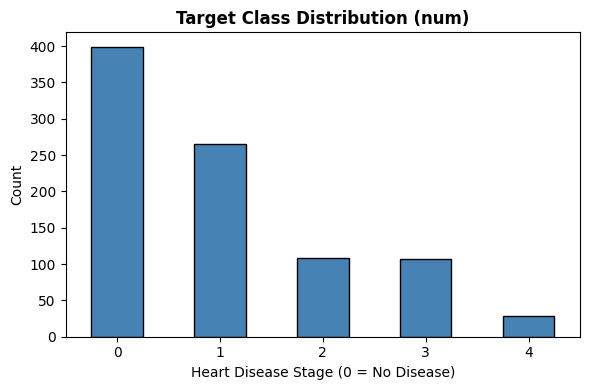

In [20]:
print("\n" + "=" * 60)
print("TASK 2 – EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Statistical Summary ---")
print(df.describe())

print("\n--- Target Class Distribution ---")
print(df['num'].value_counts())

# Plot 1: Class Distribution
fig, ax = plt.subplots(figsize=(6, 4))
df['num'].value_counts().sort_index().plot(kind='bar', ax=ax,
                                           color='steelblue', edgecolor='black')
ax.set_title('Target Class Distribution (num)', fontweight='bold')
ax.set_xlabel('Heart Disease Stage (0 = No Disease)')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=120)
plt.show()



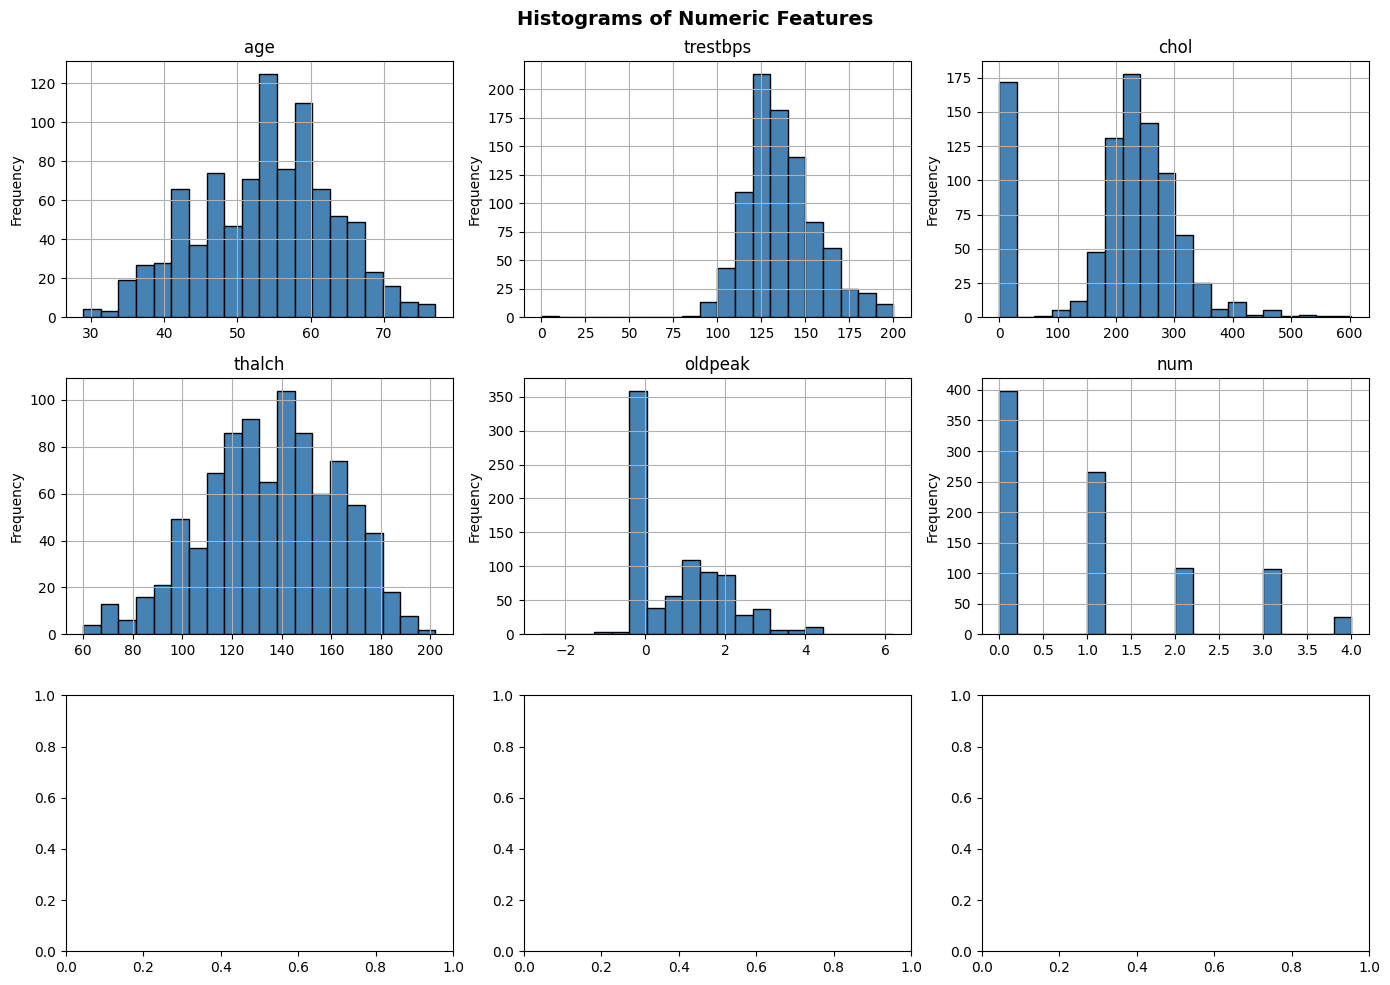

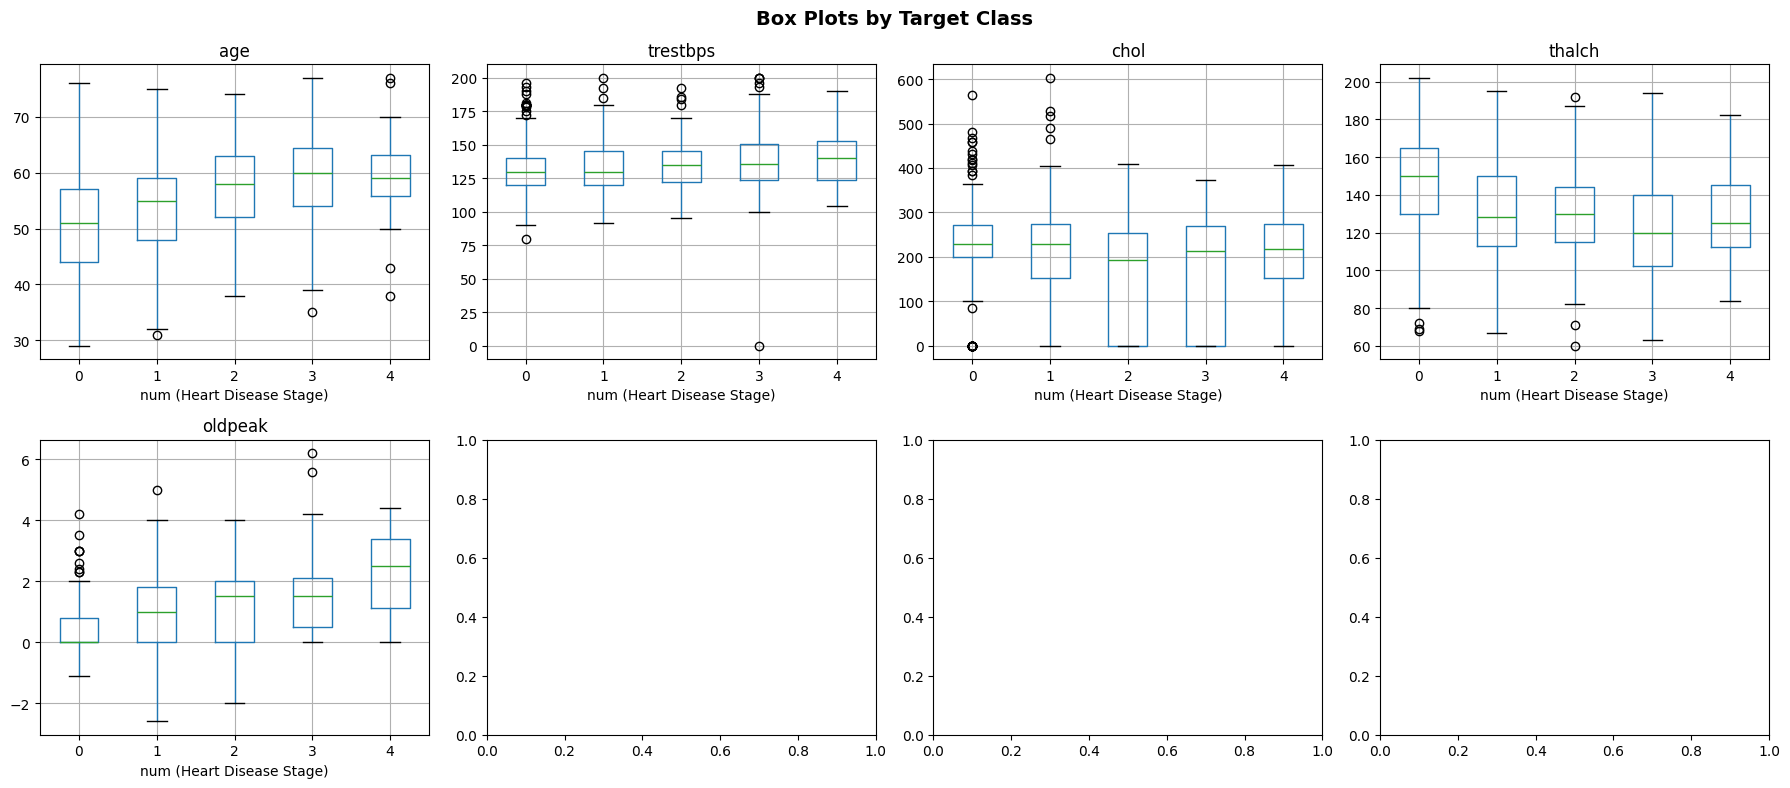

In [21]:
# Plot 2: Histograms of Numeric Features
num_cols = df.select_dtypes(include=np.number).columns.tolist()
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for i, col in enumerate(num_cols):
    ax = axes[i // 3][i % 3]
    df[col].dropna().hist(bins=20, ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_ylabel('Frequency')
plt.suptitle('Histograms of Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_histograms.png', dpi=120)
plt.show()

# Plot 3: Box Plots per Target Class
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate([c for c in num_cols if c != 'num']):
    ax = axes[i // 4][i % 4]
    df.boxplot(column=col, by='num', ax=ax)
    ax.set_xlabel('num (Heart Disease Stage)')
    ax.set_title(col)
plt.suptitle('Box Plots by Target Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_boxplots.png', dpi=120)
plt.show()

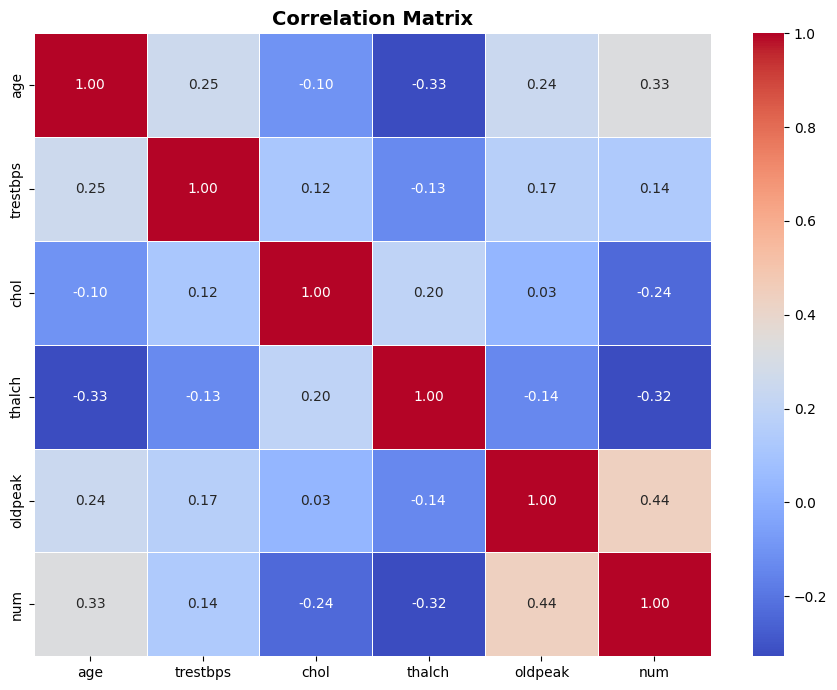

In [22]:
# Plot 4: Correlation Matrix
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', ax=ax, linewidths=0.5)
ax.set_title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_correlation_matrix.png', dpi=120)
plt.show()

In [23]:
# TASK 3 – FEATURE ENGINEERING

In [24]:
print("\n" + "=" * 60)
print("TASK 3 – FEATURE ENGINEERING")
print("=" * 60)


TASK 3 – FEATURE ENGINEERING


In [25]:
# Handle missing values in 'oldpeak' (only column with NaN)
df['oldpeak'].fillna(df['oldpeak'].median(), inplace=True)
print(f"\nFilled {62} missing 'oldpeak' values with median: {df['oldpeak'].median():.2f}")


Filled 62 missing 'oldpeak' values with median: 0.50


In [26]:
# Encode boolean-like columns
for col in ['fbs', 'exang']:
    df[col] = df[col].map(lambda x: 1 if str(x).strip().upper() in ['TRUE', '1'] else 0)

In [27]:
# Label-encode categorical columns
cat_cols = ['sex', 'cp', 'restecg', 'slope', 'thal']
le = LabelEncoder()
for col in cat_cols:
    original = df[col].unique()
    df[col] = le.fit_transform(df[col].astype(str))
    print(f"Label-encoded '{col}': {list(original)} → {list(range(len(original)))}")

Label-encoded 'sex': ['Male', 'Female'] → [0, 1]
Label-encoded 'cp': ['typical angina', 'atypical angina', 'asymptomatic', 'non-anginal'] → [0, 1, 2, 3]
Label-encoded 'restecg': ['lv hypertrophy', 'normal', 'st-t abnormality'] → [0, 1, 2]
Label-encoded 'slope': ['downsloping', 'flat', 'upsloping'] → [0, 1, 2]
Label-encoded 'thal': ['fixed defect', 'normal', 'reversable defect'] → [0, 1, 2]


In [28]:
# Create binary target: 0 = No disease, 1 = Disease (any stage)
df['target'] = (df['num'] > 0).astype(int)
print("\nBinary Target Distribution:")
print(df['target'].value_counts())


Binary Target Distribution:
target
1    509
0    399
Name: count, dtype: int64


In [29]:
X = df.drop(['num', 'target'], axis=1)
y = df['target']
print(f"\nFeatures: {X.columns.tolist()}")


Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'thal']


In [30]:
# TASK 4 – DECISION TREE CLASSIFICATION

In [31]:
print("\n" + "=" * 60)
print("TASK 4 – DECISION TREE CLASSIFICATION")
print("=" * 60)


TASK 4 – DECISION TREE CLASSIFICATION


In [32]:
# 80-20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nTraining set : {X_train.shape[0]} samples")
print(f"Testing set  : {X_test.shape[0]} samples")


Training set : 726 samples
Testing set  : 182 samples


In [33]:
# Train baseline Decision Tree
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)
y_pred_base = dt_baseline.predict(X_test)


In [34]:
print("\n--- Baseline Decision Tree Performance ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_base):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_base):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, dt_baseline.predict_proba(X_test)[:, 1]):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_base,
      target_names=['No Disease', 'Disease']))


--- Baseline Decision Tree Performance ---
Accuracy  : 0.7198
Precision : 0.7576
Recall    : 0.7353
F1-Score  : 0.7463
ROC-AUC   : 0.7176

Classification Report:
               precision    recall  f1-score   support

  No Disease       0.67      0.70      0.69        80
     Disease       0.76      0.74      0.75       102

    accuracy                           0.72       182
   macro avg       0.72      0.72      0.72       182
weighted avg       0.72      0.72      0.72       182



In [35]:
# TASK 5 – HYPERPARAMETER TUNING

In [36]:
print("\n" + "=" * 60)
print("TASK 5 – HYPERPARAMETER TUNING (GridSearchCV)")
print("=" * 60)


TASK 5 – HYPERPARAMETER TUNING (GridSearchCV)


In [39]:
param_grid = {
    'max_depth':         [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion':         ['gini', 'entropy']
}


In [40]:
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10, None],
                         'min_samples_split': [2, 5, 10]},
             scoring='f1')

In [41]:
print("\nBest Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Val F1   : {grid_search.best_score_:.4f}")


Best Hyperparameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 10}
Best Cross-Val F1   : 0.7861


In [42]:
best_dt = grid_search.best_estimator_
y_pred_best = best_dt.predict(X_test)

In [43]:
print("\n--- Tuned Decision Tree Performance ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, best_dt.predict_proba(X_test)[:, 1]):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_best,
      target_names=['No Disease', 'Disease']))


--- Tuned Decision Tree Performance ---
Accuracy  : 0.7088
Precision : 0.7579
Recall    : 0.7059
F1-Score  : 0.7310
ROC-AUC   : 0.7568

Classification Report:
               precision    recall  f1-score   support

  No Disease       0.66      0.71      0.68        80
     Disease       0.76      0.71      0.73       102

    accuracy                           0.71       182
   macro avg       0.71      0.71      0.71       182
weighted avg       0.71      0.71      0.71       182



In [44]:
# Max Depth vs Accuracy curve
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, None]
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, m.predict(X_train)))
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))

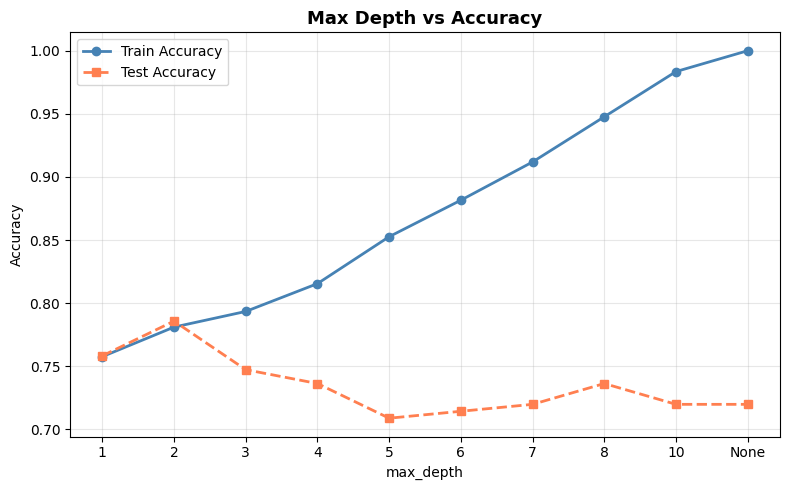

In [45]:

fig, ax = plt.subplots(figsize=(8, 5))
labels = [str(d) if d else 'None' for d in depths]
ax.plot(labels, train_acc, 'o-', label='Train Accuracy', color='steelblue', linewidth=2)
ax.plot(labels, test_acc, 's--', label='Test Accuracy', color='coral', linewidth=2)
ax.set_title('Max Depth vs Accuracy', fontweight='bold', fontsize=13)
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('depth_vs_accuracy.png', dpi=120)
plt.show()

In [46]:
# TASK 6 – MODEL EVALUATION AND ANALYSIS

In [47]:
print("\n" + "=" * 60)
print("TASK 6 – MODEL EVALUATION AND ANALYSIS")
print("=" * 60)


TASK 6 – MODEL EVALUATION AND ANALYSIS


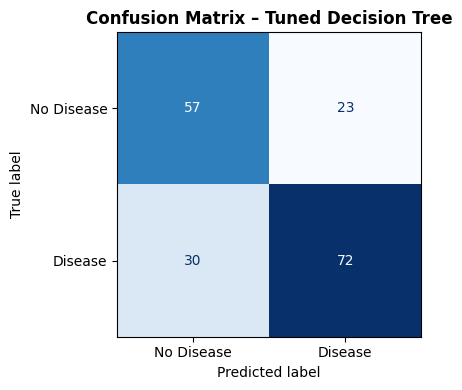

In [48]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Disease']).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix – Tuned Decision Tree', fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120)
plt.show()

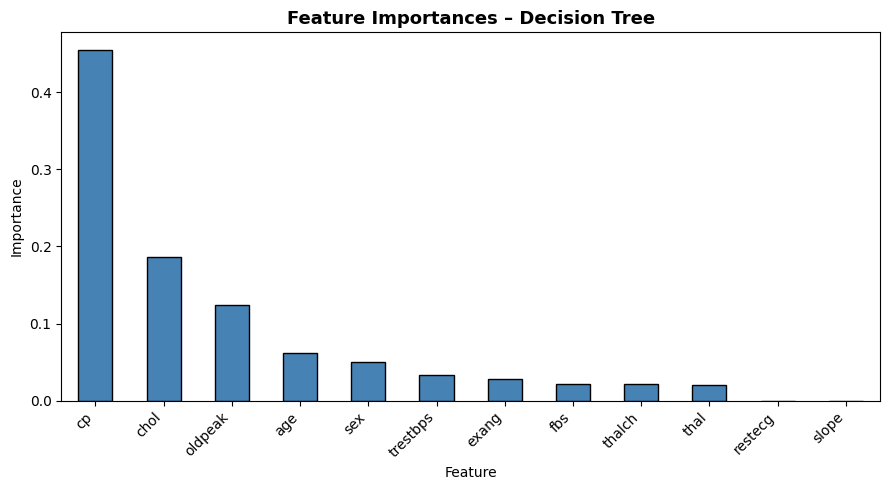


Top 5 Features:
cp         0.455325
chol       0.186454
oldpeak    0.123879
age        0.061930
sex        0.050487
dtype: float64


In [49]:
# Feature Importances
feat_imp = pd.Series(best_dt.feature_importances_,
                     index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
feat_imp.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Feature Importances – Decision Tree', fontweight='bold', fontsize=13)
ax.set_ylabel('Importance')
ax.set_xlabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120)
plt.show()
print("\nTop 5 Features:")
print(feat_imp.head())

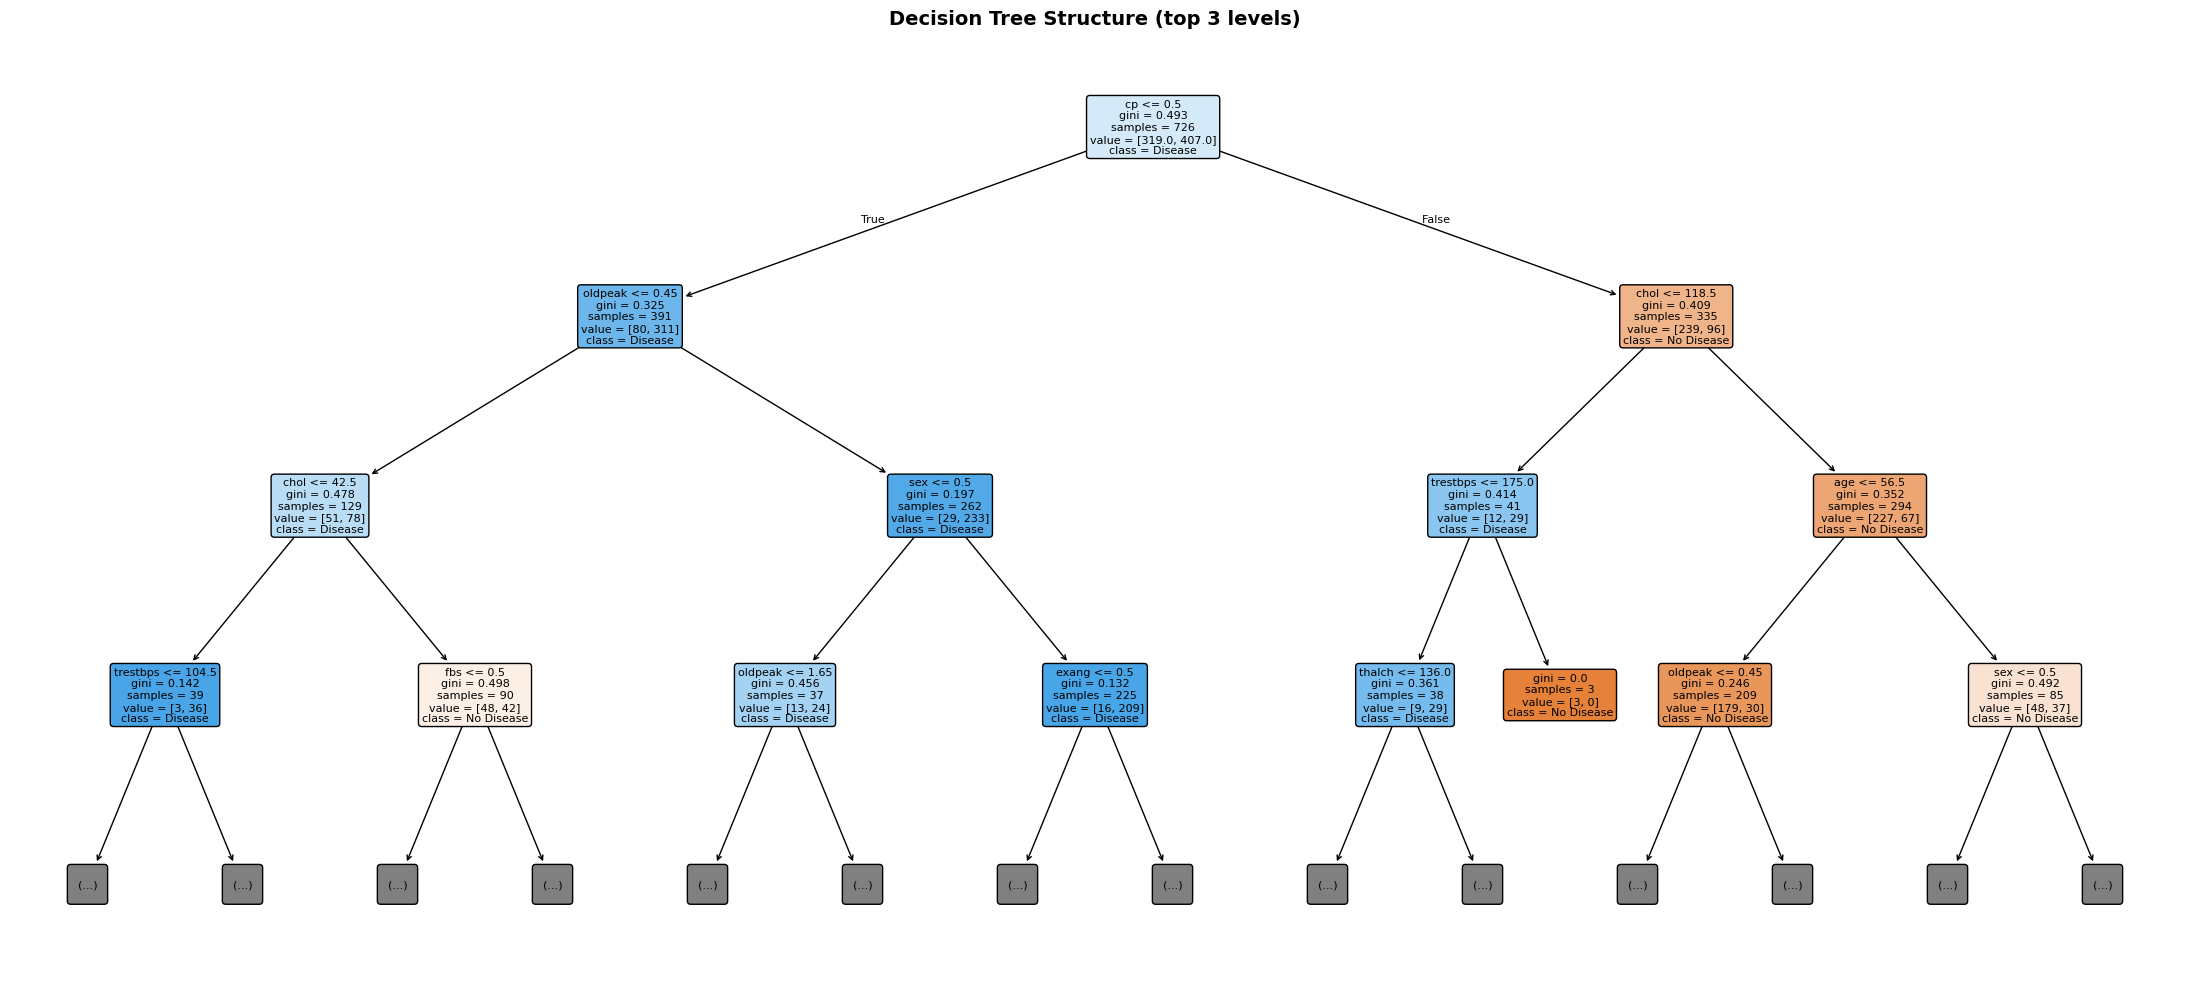

In [50]:
# Decision Tree Visualisation (top 3 levels)
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(best_dt, feature_names=X.columns,
          class_names=['No Disease', 'Disease'],
          filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title('Decision Tree Structure (top 3 levels)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('decision_tree_structure.png', dpi=100)
plt.show()


In [56]:
# Final Summary
print("\n" + "=" * 60)
print("FINAL MODEL COMPARISON SUMMARY")
print("=" * 60)

metrics = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Baseline DT': [
        round(accuracy_score(y_test, y_pred_base), 4),
        round(precision_score(y_test, y_pred_base), 4),
        round(recall_score(y_test, y_pred_base), 4),
        round(f1_score(y_test, y_pred_base), 4),
        round(roc_auc_score(y_test, dt_baseline.predict_proba(X_test)[:, 1]), 4)
    ],
    'Tuned DT': [
        round(accuracy_score(y_test, y_pred_best), 4),
        round(precision_score(y_test, y_pred_best), 4),
        round(recall_score(y_test, y_pred_best), 4),
        round(f1_score(y_test, y_pred_best), 4),
        round(roc_auc_score(y_test, best_dt.predict_proba(X_test)[:, 1]), 4)
    ]
}

import pandas as pd
print(pd.DataFrame(metrics).to_string(index=False))


FINAL MODEL COMPARISON SUMMARY
   Metric  Baseline DT  Tuned DT
 Accuracy       0.7198    0.7088
Precision       0.7576    0.7579
   Recall       0.7353    0.7059
 F1-Score       0.7463    0.7310
  ROC-AUC       0.7176    0.7568


In [57]:
# INTERVIEW QUESTIONS (Answers)

In [59]:
print("\n" + "=" * 60)
print("INTERVIEW QUESTIONS")
print("=" * 60)

print("""
Q1. Common hyperparameters of decision tree models:

  - max_depth         : Limits how deep the tree grows.
                        Lower values → simpler tree, less overfitting.
                        Higher values → more complex, may overfit.

  - min_samples_split : Minimum samples needed to split a node.
                        Higher values → fewer splits, reduces overfitting.

  - min_samples_leaf  : Minimum samples required at a leaf node.
                        Higher values → smoother decision boundary.

  - criterion         : 'gini' (Gini impurity) or 'entropy' (Information Gain).
                        Both measure split quality; entropy is slightly slower.

  - max_features      : Number of features considered for each split.
                        Reduces variance; useful for high-dimensional data.

  - splitter          : 'best' selects the best split; 'random' selects randomly.


Q2. Label Encoding vs One-Hot Encoding:

  Label Encoding:
    - Assigns each category a unique integer (e.g., Cat→0, Dog→1, Bird→2).
    - Implies an ordinal relationship between categories.
    - Suitable for ordinal features (e.g., Low/Medium/High) or tree-based models.
    - Problem: May mislead distance-based models (SVM, KNN) by implying order.

  One-Hot Encoding:
    - Creates a new binary column for each category.
    - No ordinal relationship assumed.
    - Example: 'cp' with 4 values → 4 binary columns.
    - Suitable for nominal features and linear/distance-based models.
    - Problem: Can cause dimensionality explosion with many categories.
""")



INTERVIEW QUESTIONS

Q1. Common hyperparameters of decision tree models:

  - max_depth         : Limits how deep the tree grows.
                        Lower values → simpler tree, less overfitting.
                        Higher values → more complex, may overfit.

  - min_samples_split : Minimum samples needed to split a node.
                        Higher values → fewer splits, reduces overfitting.

  - min_samples_leaf  : Minimum samples required at a leaf node.
                        Higher values → smoother decision boundary.

  - criterion         : 'gini' (Gini impurity) or 'entropy' (Information Gain).
                        Both measure split quality; entropy is slightly slower.

  - max_features      : Number of features considered for each split.
                        Reduces variance; useful for high-dimensional data.

  - splitter          : 'best' selects the best split; 'random' selects randomly.


Q2. Label Encoding vs One-Hot Encoding:

  Label Encoding:
    -